# PointLLM-7B on Google Colab (with .ply upload UI)

**Before you start:** Runtime -> Change runtime type -> **T4 GPU** (free tier works for the 7B model in float16, ~14 GB VRAM). If model loading crashes with an out-of-memory error on *system RAM*, switch to a High-RAM runtime (Colab Pro).

Run the cells in order. This notebook was written without being able to execute it on a GPU, so the "smoke test" in step 5 is there to catch problems early, before the large model download.

Why a separate Python 3.10 environment? The repo was tested with Python 3.10 / PyTorch 2.0.1 / Transformers 4.28 dev. Colab's default Python is newer and those pins usually don't install there, so we create a matching environment with `uv` and run the app inside it.

## 1. Check the GPU

In [1]:
!nvidia-smi
!free -h | head -2

Fri Oct 16 19:58:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Clone the repo (HTTPS, since the README's `git@` SSH URL won't work on Colab)

In [2]:
%cd /content
!git clone https://github.com/InternRobotics/PointLLM.git

/content
Cloning into 'PointLLM'...
remote: Enumerating objects: 289, done.
remote: Counting objects: 100% (147/147), done.
remote: Compressing objects: 100% (58/58), done.
remote: Total 289 (delta 109), reused 89 (delta 89), pack-reused 142 (from 1)
Receiving objects: 100% (289/289), 3.51 MiB | 19.63 MiB/s, done.
Resolving deltas: 100% (140/140), done.


## 3. Create a Python 3.10 environment and install dependencies (takes several minutes)

In [3]:
%%bash
set -e
pip -q install uv
uv venv --python 3.10 /content/venv
cd /content/PointLLM
PY=/content/venv/bin/python
uv pip install --python $PY "torch==2.0.1" "numpy<2"
uv pip install --python $PY -e . "numpy<2"
uv pip install --python $PY accelerate "open3d==0.18.0" matplotlib "numpy<2"
$PY -c "import torch, open3d, gradio, transformers; print('torch', torch.__version__, '| cuda', torch.cuda.is_available(), '| transformers', transformers.__version__, '| gradio', gradio.__version__)"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 64.5 MB/s eta 0:00:00
torch 2.14.1+cu130 | cuda True | transformers 4.28.0.dev0 | gradio 6.17.3


Using CPython 3.10.22
Creating virtual environment at: venv
Activate with: source venv/bin/activate
Using Python 3.10.22 environment at: /content/venv
Resolved 26 packages in 562ms
Prepared 26 packages in 4m 32s
Installed 26 packages in 354ms
 + cmake==4.4.4
 + filelock==4.1.0
 + jinja2==3.1.6
 + lit==23.1.3
 + markupsafe==3.0.4
 + mpmath==1.3.0
 + networkx==3.4.2
 + numpy==1.26.4
 + nvidia-cublas-cu11==11.10.3.66
 + nvidia-cuda-cupti-cu11==11.7.101
 + nvidia-cuda-nvrtc-cu11==11.7.99
 + nvidia-cuda-runtime-cu11==11.7.99
 + nvidia-cudnn-cu11==8.5.0.96
 + nvidia-cufft-cu11==10.9.0.58
 + nvidia-curand-cu11==10.2.10.91
 + nvidia-cusolver-cu11==11.4.0.1
 + nvidia-cusparse-cu11==11.7.4.91
 + nvidia-nccl-cu11==2.14.3
 + nvidia-nvtx-cu11==11.7.91
 + packaging==26.3
 + setuptools==84.0.0
 + sympy==1.14.0
 + torch==2.0.1
 + triton==2.0.0
 + typing-extensions==4.16.0
 + wheel==0.48.0
Using Python 3.10.22 environment at: /content/venv
Resolved 182 packages in 21.16s
Prepared 172 packages in 1m 23s

## 4. Write the helper module (loading, preprocessing, inference)

In [4]:
%%writefile /content/PointLLM/pointllm_colab.py
import io
import numpy as np
import torch
from transformers import AutoTokenizer
from pointllm.conversation import conv_templates, SeparatorStyle
from pointllm.utils import disable_torch_init
from pointllm.model import PointLLMLlamaForCausalLM
from pointllm.model.utils import KeywordsStoppingCriteria

MODEL_NAME = "RunsenXu/PointLLM_7B_v1.2"
DTYPE = torch.float16  # T4 has no bfloat16 support


def load_model(model_name=MODEL_NAME, dtype=DTYPE):
    disable_torch_init()
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    try:
        # stream weights straight to the GPU to avoid needing ~14 GB of system RAM
        model = PointLLMLlamaForCausalLM.from_pretrained(
            model_name, low_cpu_mem_usage=True, use_cache=True,
            torch_dtype=dtype, device_map={"": 0})
    except Exception as e:
        print("device_map loading failed, falling back to .cuda():", repr(e))
        torch.cuda.empty_cache()
        model = PointLLMLlamaForCausalLM.from_pretrained(
            model_name, low_cpu_mem_usage=False, use_cache=True,
            torch_dtype=dtype).cuda()
    model.initialize_tokenizer_point_backbone_config_wo_embedding(tokenizer)
    model.eval()
    return model, tokenizer


def _rot_x(deg):
    t = np.deg2rad(deg)
    c, s = np.cos(t), np.sin(t)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]], dtype=np.float32)


ROTATIONS = {
    "None": np.eye(3, dtype=np.float32),
    "+90 deg about X": _rot_x(90),
    "-90 deg about X": _rot_x(-90),
    "180 deg about X": _rot_x(180),
}


def preprocess_ply(path, n_points=8192, rotation="None", seed=0):
    # returns ((n_points, 6) float32 array: xyz normalised to unit sphere + rgb in [0,1], has_color)
    import open3d as o3d
    rng = np.random.default_rng(seed)

    mesh = o3d.io.read_triangle_mesh(path)
    if len(mesh.triangles) > 0 and mesh.has_vertex_colors():
        pcd = mesh.sample_points_uniformly(number_of_points=60000)  # mesh -> evenly spread points
    else:
        pcd = o3d.io.read_point_cloud(path)

    xyz = np.asarray(pcd.points, dtype=np.float32)
    if len(xyz) == 0:
        raise ValueError("No points found in file")
    has_color = pcd.has_colors()
    rgb = np.clip(np.asarray(pcd.colors, dtype=np.float32), 0, 1) if has_color else np.full_like(xyz, 0.5)

    if len(xyz) > 40000:  # cheap random pre-reduction so farthest point sampling stays fast
        idx = rng.choice(len(xyz), 40000, replace=False)
        xyz, rgb = xyz[idx], rgb[idx]

    if len(xyz) >= n_points:
        p = o3d.geometry.PointCloud()
        p.points = o3d.utility.Vector3dVector(xyz.astype(np.float64))
        p.colors = o3d.utility.Vector3dVector(rgb.astype(np.float64))
        p = p.farthest_point_down_sample(n_points)
        xyz = np.asarray(p.points, dtype=np.float32)
        rgb = np.asarray(p.colors, dtype=np.float32)
    else:  # too few points: resample with replacement
        idx = rng.choice(len(xyz), n_points, replace=True)
        xyz, rgb = xyz[idx], rgb[idx]

    xyz = xyz @ ROTATIONS[rotation].T
    xyz = xyz - xyz.mean(axis=0)
    xyz = xyz / np.max(np.linalg.norm(xyz, axis=1))
    return np.concatenate([xyz, rgb], axis=1).astype(np.float32), has_color


def preview(points):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from PIL import Image
    xyz, rgb = points[:, :3], points[:, 3:]
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, (a, b, name) in zip(axes, [(0, 1, "X-Y"), (0, 2, "X-Z"), (1, 2, "Y-Z")]):
        ax.scatter(xyz[:, a], xyz[:, b], c=rgb, s=1)
        ax.set_title(name)
        ax.set_aspect("equal")
        ax.axis("off")
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=80, bbox_inches="tight")
    plt.close(fig)
    buf.seek(0)
    return Image.open(buf).convert("RGB")


@torch.inference_mode()
def ask(model, tokenizer, points, prompt, sample=False):
    cfg = model.get_model().point_backbone_config
    use_start_end = getattr(model.config, "mm_use_point_start_end", False)
    conv = conv_templates["vicuna_v1_1"].copy()

    patch = cfg["default_point_patch_token"] * cfg["point_token_len"]
    if use_start_end:
        qs = cfg["default_point_start_token"] + patch + cfg["default_point_end_token"] + "\n" + prompt
    else:
        qs = patch + "\n" + prompt
    conv.append_message(conv.roles[0], qs)
    conv.append_message(conv.roles[1], None)

    input_ids = torch.as_tensor(tokenizer([conv.get_prompt()]).input_ids).cuda()
    stop_str = conv.sep if conv.sep_style != SeparatorStyle.TWO else conv.sep2
    stopping = KeywordsStoppingCriteria([stop_str], tokenizer, input_ids)
    pc = torch.from_numpy(points).unsqueeze(0).to(model.dtype).cuda()

    kw = dict(do_sample=True, temperature=1.0, top_k=50, top_p=0.95) if sample else dict(do_sample=False)
    out = model.generate(input_ids, point_clouds=pc, max_length=2048,
                         stopping_criteria=[stopping], **kw)
    ans = tokenizer.batch_decode(out[:, input_ids.shape[1]:], skip_special_tokens=True)[0].strip()
    if ans.endswith(stop_str):
        ans = ans[:-len(stop_str)].strip()
    return ans

Writing /content/PointLLM/pointllm_colab.py


## 5. Write the Gradio app (single-object tab + batch tab with CSV export)

In [5]:
%%writefile /content/PointLLM/app.py
import csv
import os
import tempfile
import gradio as gr
from pointllm_colab import load_model, preprocess_ply, preview, ask, ROTATIONS

print("Loading PointLLM-7B (first run downloads the weights, this can take a while)...", flush=True)
model, tokenizer = load_model()
print("Model loaded.", flush=True)

PROMPTS = ["What is this?", "This is an object of ", "Caption this 3D model in detail."]


def _path(f):
    return f if isinstance(f, str) else f.name  # gradio 3.x gives a tempfile wrapper, 4.x+ a path


def run_single(file, prompt, rotation, sample):
    if file is None:
        return None, "Please upload a .ply file."
    try:
        pts, has_color = preprocess_ply(_path(file), rotation=rotation)
        ans = ask(model, tokenizer, pts, prompt, sample)
    except Exception as e:
        return None, "ERROR: " + repr(e)
    if not has_color:
        ans += "\n\n[warning: the file had no color, so a gray placeholder was used]"
    return preview(pts), ans


def run_batch(files, prompt, rotation, sample):
    rows = []
    for f in files or []:
        p = _path(f)
        try:
            pts, _ = preprocess_ply(p, rotation=rotation)
            ans = ask(model, tokenizer, pts, prompt, sample)
        except Exception as e:
            ans = "ERROR: " + repr(e)
        rows.append([os.path.basename(p), prompt, ans])
    out_path = os.path.join(tempfile.mkdtemp(), "pointllm_results.csv")
    with open(out_path, "w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["file", "prompt", "response"])
        w.writerows(rows)
    return rows, out_path


with gr.Blocks(title="PointLLM") as demo:
    gr.Markdown("# PointLLM: chat about your own colored point cloud (.ply)")
    with gr.Tab("Single object"):
        with gr.Row():
            with gr.Column():
                f1 = gr.File(label="Point cloud (.ply)", file_types=[".ply"])
                p1 = gr.Textbox(label="Prompt", value=PROMPTS[0])
                gr.Examples([[p] for p in PROMPTS], inputs=p1, label="Paper prompts (classification I / C, captioning)")
                r1 = gr.Dropdown(list(ROTATIONS), value="None", label="Rotate before inference (try if results look off)")
                s1 = gr.Checkbox(False, label="Random sampling (default is deterministic)")
                b1 = gr.Button("Run", variant="primary")
            with gr.Column():
                img = gr.Image(label="What the model sees: 8192 points, 3 views")
                out1 = gr.Textbox(label="PointLLM answer", lines=8)
        b1.click(run_single, [f1, p1, r1, s1], [img, out1])

    with gr.Tab("Batch (many files -> CSV)"):
        f2 = gr.File(label="Point clouds (.ply)", file_types=[".ply"], file_count="multiple")
        p2 = gr.Textbox(label="Prompt", value=PROMPTS[0])
        r2 = gr.Dropdown(list(ROTATIONS), value="None", label="Rotate before inference")
        s2 = gr.Checkbox(False, label="Random sampling")
        b2 = gr.Button("Run batch", variant="primary")
        tbl = gr.Dataframe(headers=["file", "prompt", "response"], label="Results")
        csvf = gr.File(label="Download results CSV")
        b2.click(run_batch, [f2, p2, r2, s2], [tbl, csvf])

demo.queue().launch(server_name="0.0.0.0", server_port=7860,
                    share=os.environ.get("SHARE") == "1")

Writing /content/PointLLM/app.py


## 6. Smoke test: check the repo imports match (fast, before downloading ~14 GB of weights)

In [6]:
%%bash
cd /content/PointLLM
PYTHONPATH=/content/PointLLM /content/venv/bin/python -c "import pointllm_colab; print('imports OK')"

imports OK


/content/venv/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


**If step 6 fails with an ImportError/AttributeError**, the repo's API differs from what I wrote. Print the official chat script and compare names (`init_model`, the conversation template, the point-token handling) with `pointllm_colab.py`:

In [7]:
!sed -n 1,140p /content/PointLLM/pointllm/eval/PointLLM_chat.py

import argparse
from transformers import AutoTokenizer
import torch
import os
from pointllm.conversation import conv_templates, SeparatorStyle
from pointllm.utils import disable_torch_init
from pointllm.model import *
from pointllm.model.utils import KeywordsStoppingCriteria

from pointllm.data import load_objaverse_point_cloud

import os

def load_point_cloud(args):
    object_id = args.object_id
    print(f"[INFO] Loading point clouds using object_id: {object_id}")
    point_cloud = load_objaverse_point_cloud(args.data_path, object_id, pointnum=8192, use_color=True)
    
    return object_id, torch.from_numpy(point_cloud).unsqueeze_(0).to(torch.float32)

def init_model(args):
    # Model
    disable_torch_init()

    model_path = args.model_path 
    print(f'[INFO] Model name: {model_path}')

    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = PointLLMLlamaForCausalLM.from_pretrained(model_path, low_cpu_mem_usage=False, use_cache=True, torch_dtype=args.torch_dtype).

## 7. Launch the app in the background (downloads the model on first run; wait for READY)

In [8]:
import subprocess, time, os

log_path = "/content/app.log"
log = open(log_path, "w")
env = {**os.environ, "PYTHONPATH": "/content/PointLLM"}
# env["SHARE"] = "1"   # uncomment for a public gradio.live link (anyone with the URL can use your GPU)
proc = subprocess.Popen(["/content/venv/bin/python", "-u", "/content/PointLLM/app.py"],
                        cwd="/content/PointLLM", env=env, stdout=log, stderr=subprocess.STDOUT)

started = False
for _ in range(180):          # waits up to ~30 minutes
    time.sleep(10)
    txt = open(log_path).read()
    if "Running on" in txt:
        started = True
        break
    if proc.poll() is not None:
        break
print(txt[-3000:])
print("READY: run the next cell" if started else "NOT READY: read the log above")

/content/venv/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Loading PointLLM-7B (first run downloads the weights, this can take a while)...
/content/venv/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(

Loading PointBERT config from /content/PointLLM/pointllm/model/pointbert/PointTransformer_8192point_2layer.yaml.

Loading checkpoint shards: 100%|██████████| 3/3 [02:06<00:00, 42.19s/it]
Model loaded.
* Running on local URL:  http://0.0.0.0:7860
* To create a public link, set `share=True` in `launch()`.

READY: run the next cell


## 8. Open the interface (upload your `.ply` files here)

In [9]:
from google.colab import output
output.serve_kernel_port_as_iframe(7860, height=950)
# If the embedded view misbehaves, open it in its own tab instead:
# output.serve_kernel_port_as_window(7860)

<IPython.core.display.Javascript object>

In [10]:
from google.colab import output
# Run this if the embedded iframe doesn't show up. It opens the interface in a new window/tab.
output.serve_kernel_port_as_window(7860)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

## 9. Stop the app when done (frees the GPU)

In [11]:
proc.terminate()

Loading the model (the first load can take a few minutes)...
/content/venv/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/content/venv/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possi
  warnings.warn(
Loading PointBERT config from /content/PointLLM/pointllm/model/pointbert/PointTransformer_8192point_2layer.yaml.
Loading checkpoint shards: 100%|██████████| 3/3 [02:04<00:00, 41.62s/it]
Model ready.

Commands at the file prompt:  u = upload .ply files | r = change rotation | q = quit
Questions: type 1 / 2 / 3 for the paper prompts, or write your own. Press Enter to pick another file.

Files: none yet (type u to upload)
File name or path > /content/poly.ply
Question (Enter = other file) > What is this object?


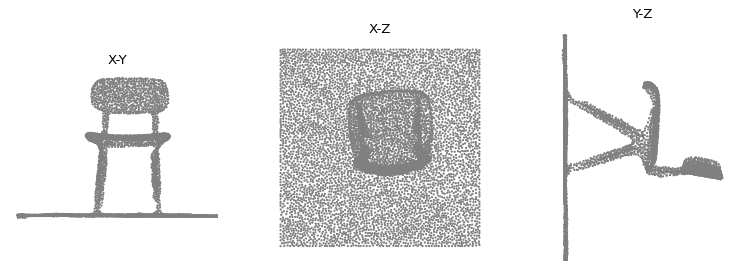

[warning: no color in this file, so a gray placeholder was used]
PointLLM: This is a 3D model of a chair.
Question (Enter = other file) > Is the chair being hanged or is it sitting on something?
[warning: no color in this file, so a gray placeholder was used]
PointLLM: The chair is sitting on a white mat.
Question (Enter = other file) > describe the type of chair
[warning: no color in this file, so a gray placeholder was used]
PointLLM: The chair is a modern, minimalist, and monochrome representation, lacking any color or pattern.
Question (Enter = other file) > Does the chair have any arm rests?
[warning: no color in this file, so a gray placeholder was used]
PointLLM: No, the chair does not have any arm rests.
Question (Enter = other file) > Does the chair have back support?
[warning: no color in this file, so a gray placeholder was used]
PointLLM: No, the chair does not have back support.
Question (Enter = other file) > How many legs does this object have?
[warning: no color in this

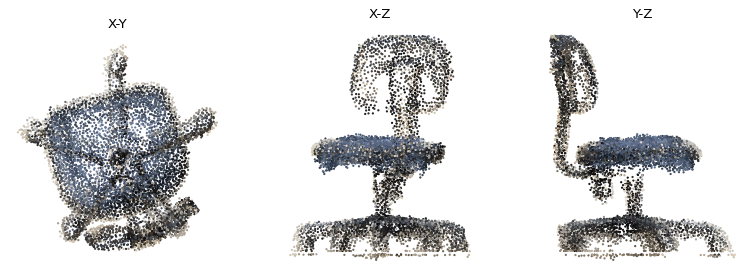

PointLLM: This is a 3D model of a chair that features a unique design. The chair is predominantly white, with a distinctive blue pattern adorning the seat and backrest. The chair is supported by four sturdy legs, each equipped with a convenient handle for easy mobility. The chair's design suggests it could be used in a variety of settings, from home use for relaxation to commercial establishments for customer seating, due to its versatile aesthetic appeal.
Question (Enter = other file) > 

Files: ['poly.ply', 'processed_Chair_1_8192pts_model.ply']
File name or path > /content/processed_Chair_1_8192pts_model.ply
Question (Enter = other file) > Describe the image


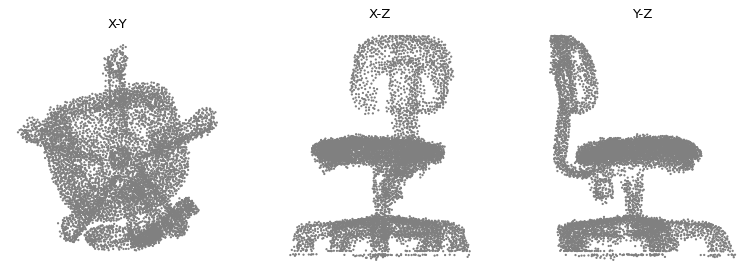

[warning: no color in this file, so a gray placeholder was used]
PointLLM: The image is a 3D model of a simplistic, cartoon-style white chair.
Question (Enter = other file) > Is the chair being hanged or is it sitting on something?
[warning: no color in this file, so a gray placeholder was used]
PointLLM: The chair is sitting on a wooden branch.
Question (Enter = other file) > Does the chair have arm rests?
[warning: no color in this file, so a gray placeholder was used]
PointLLM: No, the chair does not have arm rests.
Question (Enter = other file) > How many legs does the chair have?
[warning: no color in this file, so a gray placeholder was used]
PointLLM: The chair has four legs.
Question (Enter = other file) > 

Files: ['Chair_7.ply', 'poly.ply', 'processed_Chair_1_8192pts_model.ply']
File name or path > /content/Chair_7.ply
Question (Enter = other file) > What is this object?


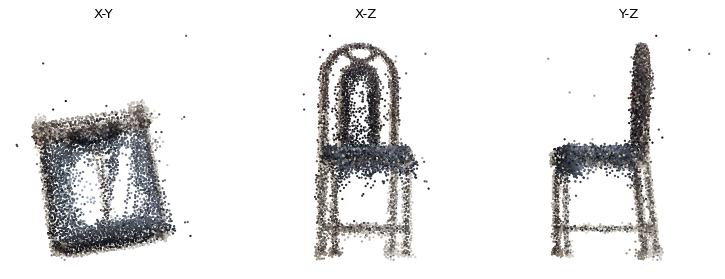

PointLLM: This is a 3D model of a chair.
Question (Enter = other file) > How many legs does it have?
PointLLM: It has four legs.
Question (Enter = other file) > I see 6 legs
PointLLM: The object is a chair, not a table. It has four legs.
Question (Enter = other file) > Is something connecting the legs? What is the closest english alphabet of that thing?
PointLLM: Yes, there is a thin, rectangular board connecting the legs.
Question (Enter = other file) > It is a 2D image or a 3D object?
PointLLM: It is a 3D object.
Question (Enter = other file) > Are there holes in the chair?
PointLLM: Yes, there are holes in the seat and the backrest of the chair.
Question (Enter = other file) > Is this a good chair for making out?
PointLLM: Yes, this chair is perfect for making out because of its candle-like structure that provides a cozy and intimate setting.
Question (Enter = other file) > What is the general geometric shape of the backrest?
PointLLM: The backrest has a rectangular, slatted design.

In [ ]:
# ===== Terminal-style chat for PointLLM (replaces the Gradio step) =====
import subprocess, os, json, time, glob
from IPython.display import display, Image

WORKER = r"""
import sys, json, traceback
sys.path.insert(0, "/content/PointLLM")
from pointllm_colab import load_model, preprocess_ply, preview, ask

model, tokenizer = load_model()
print("@@READY@@", flush=True)

for line in sys.stdin:
    line = line.strip()
    if not line:
        continue
    try:
        req = json.loads(line)
        pts, has_color = preprocess_ply(req["path"], rotation=req.get("rotation", "None"))
        preview(pts).save("/content/last_preview.png")
        ans = ask(model, tokenizer, pts, req["prompt"], req.get("sample", False))
        res = {"answer": ans, "has_color": has_color}
    except Exception:
        res = {"error": traceback.format_exc()}
    print("@@RESULT@@" + json.dumps(res), flush=True)
"""
WORKER_PATH = "/content/PointLLM/worker.py"
with open(WORKER_PATH, "w") as fh:
    fh.write(WORKER)


def start_worker():
    # free the GPU if the Gradio app from the previous step is still running
    try:
        proc.terminate()
        proc.wait(timeout=30)
    except Exception:
        pass
    subprocess.run(["pkill", "-f", "/content/PointLLM/app.py"])
    time.sleep(5)
    env = {**os.environ, "PYTHONPATH": "/content/PointLLM"}
    w = subprocess.Popen(["/content/venv/bin/python", "-u", WORKER_PATH], cwd="/content/PointLLM",
                         env=env, stdin=subprocess.PIPE, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, bufsize=1)
    print("Loading the model (the first load can take a few minutes)...")
    while True:
        line = w.stdout.readline()
        if not line:
            raise RuntimeError("The worker exited while loading. Read the messages above.")
        if "@@READY@@" in line:
            break
        if line.strip():
            print(line.rstrip()[:200])
    print("Model ready.")
    return w


if "worker" not in globals() or worker.poll() is not None:
    worker = start_worker()


def ask_pointllm(path, prompt, rotation="None", sample=False):
    worker.stdin.write(json.dumps({"path": path, "prompt": prompt,
                                   "rotation": rotation, "sample": sample}) + "\n")
    worker.stdin.flush()
    while True:
        line = worker.stdout.readline()
        if not line:
            raise RuntimeError("The worker died. Re-run this cell to restart it.")
        if line.startswith("@@RESULT@@"):
            return json.loads(line[len("@@RESULT@@"):])


UPLOAD_DIR = "/content/uploads"
os.makedirs(UPLOAD_DIR, exist_ok=True)
PRESETS = {"1": "What is this?", "2": "This is an object of ", "3": "Caption this 3D model in detail."}
ROTATIONS = {"0": "None", "1": "+90 deg about X", "2": "-90 deg about X", "3": "180 deg about X"}
rotation = "None"


def resolve(s):
    s = s.strip().strip("'\"")
    for p in (s, os.path.join(UPLOAD_DIR, s), os.path.join("/content", s)):
        if os.path.isfile(p):
            return p
    return None


print("\nCommands at the file prompt:  u = upload .ply files | r = change rotation | q = quit")
print("Questions: type 1 / 2 / 3 for the paper prompts, or write your own. Press Enter to pick another file.")
while True:
    found = sorted(glob.glob(UPLOAD_DIR + "/*.ply") + glob.glob("/content/*.ply"))
    print("\nFiles:", [os.path.basename(f) for f in found] or "none yet (type u to upload)")
    s = input("File name or path > ").strip()
    if s.lower() == "q":
        print("Left the loop. The model stays loaded; re-run this cell to continue, or run worker.terminate() to free the GPU.")
        break
    if s.lower() == "u":
        from google.colab import files
        for name, data in files.upload().items():
            with open(os.path.join(UPLOAD_DIR, name), "wb") as fh:
                fh.write(data)
        continue
    if s.lower() == "r":
        print("Rotation:", ROTATIONS)
        rotation = ROTATIONS.get(input("Choose 0-3 > ").strip(), rotation)
        print("Rotation is now:", rotation)
        continue
    path = resolve(s)
    if path is None:
        print("File not found:", s)
        continue
    shown = False
    while True:
        q = input("Question (Enter = other file) > ")
        if not q.strip():
            break
        q = PRESETS.get(q.strip(), q)
        res = ask_pointllm(path, q, rotation)
        if "error" in res:
            print(res["error"])
            continue
        if not shown:
            display(Image(filename="/content/last_preview.png"))
            shown = True
        if not res["has_color"]:
            print("[warning: no color in this file, so a gray placeholder was used]")
        print("PointLLM:", res["answer"])